In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = 128
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2   
)

# Training set (80%)
train_generator = train_datagen.flow_from_directory(
    "data/train",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

# Validation set (20%)
val_generator = train_datagen.flow_from_directory(
    "data/train",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

# Test set 
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
    "data/test",
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


Found 4019 images belonging to 5 classes.
Found 1003 images belonging to 5 classes.
Found 860 images belonging to 5 classes.


In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

num_classes = 5

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(img_size, img_size, 3)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


In [10]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,
    verbose=1
)


Epoch 1/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 30s 234ms/step - accuracy: 0.6902 - loss: 0.8192 - val_accuracy: 0.5783 - val_loss: 1.5984
Epoch 2/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 230ms/step - accuracy: 0.7795 - loss: 0.5758 - val_accuracy: 0.6361 - val_loss: 1.4739
Epoch 3/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 230ms/step - accuracy: 0.8184 - loss: 0.4919 - val_accuracy: 0.6311 - val_loss: 1.5271
Epoch 4/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 230ms/step - accuracy: 0.8151 - loss: 0.4634 - val_accuracy: 0.6361 - val_loss: 1.3934
Epoch 5/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 232ms/step - accuracy: 0.8308 - loss: 0.4352 - val_accuracy: 0.6321 - val_loss: 1.4991
Epoch 6/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 229ms/step - accuracy: 0.8398 - loss: 0.4218 - val_accuracy: 0.6231 - val_loss: 1.7590
Epoch 7/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 30s 234ms/step - accuracy: 0.8574 - loss: 0.3862 - val_accuracy: 0.6401 - val_loss: 1.6419
Epoch 8/25
126/126 ━━━━━━━━━━━━━━━━━━━━ 29s 231ms/step - accuracy: 0.8445 - loss: 0

In [11]:
loss, acc = model.evaluate(test_generator)
print(f"✅ Test Accuracy: {acc:.2f}")


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8663 - loss: 0.5667
✅ Test Accuracy: 0.87


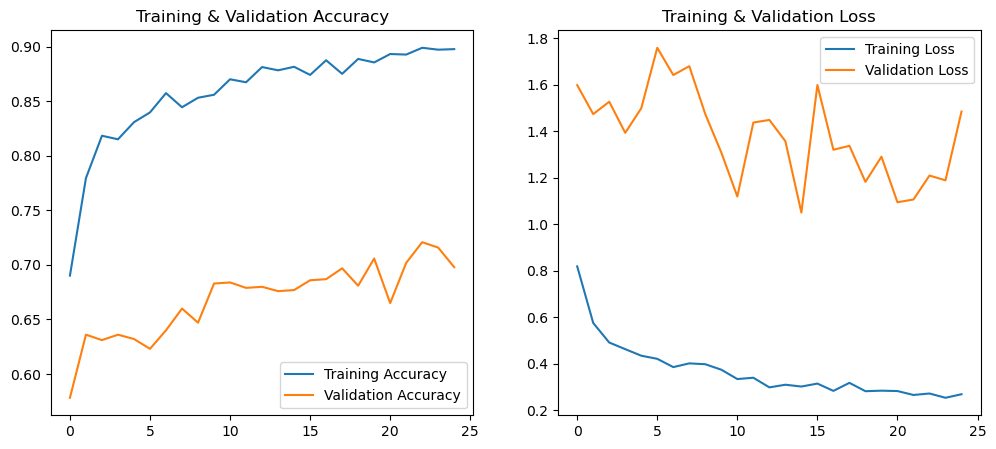

In [12]:
import matplotlib.pyplot as plt

def plot_training(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training & Validation Accuracy')

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training & Validation Loss')

    plt.show()

# After training:
plot_training(history)


27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step 
Classification Report:
                precision    recall  f1-score   support

        Blight       0.96      0.70      0.81       172
   Common_Rust       0.95      1.00      0.97       172
Gray_Leaf_Spot       0.66      0.97      0.79       172
       Healthy       0.93      0.99      0.96       172
         Other       0.98      0.67      0.80       172

      accuracy                           0.87       860
     macro avg       0.90      0.87      0.87       860
  weighted avg       0.90      0.87      0.87       860



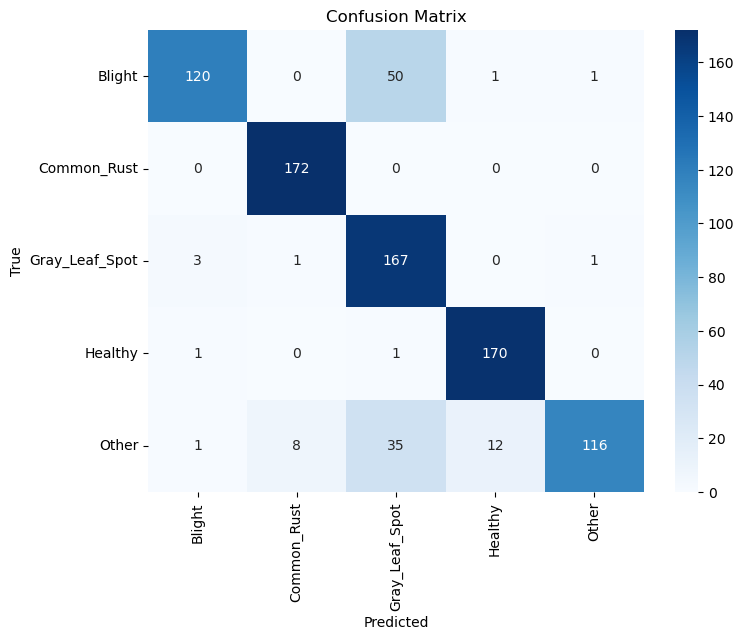

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

# Predictions on test set
y_pred = model.predict(test_generator)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Text report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_labels))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


In [14]:
model.save("models/maize_cnn.h5")